Train: (455, 30) | Test: (114, 30)

                          Model  Accuracy  Precision(M)  Recall(M)  F1(M)  Train time (s)
Logistic Regression (Baseline)    0.9825        0.9762     0.9762 0.9762          0.0517
                 Random Forest    0.9561        0.9512     0.9286 0.9398          0.4970
             Gradient Boosting    0.9561        0.9744     0.9048 0.9383          0.9062

Best model (by malignant recall / F1): Logistic Regression (Baseline)

Effect of number of trees in Random Forest:
 Trees Accuracy Time (s)
    1 0.9474 0.008
   10 0.9386 0.028
   50 0.9561 0.113
  100 0.9561 0.263
  200 0.9561 0.589
  500 0.9561 1.325


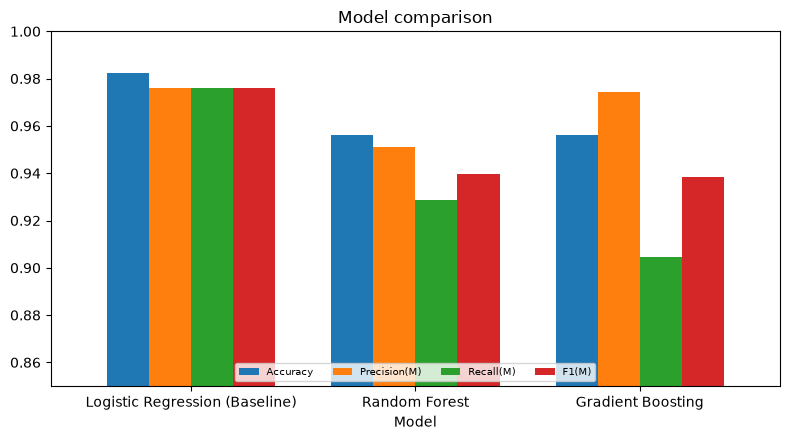

In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

X, y = load_breast_cancer(return_X_y=True) # malignant (label 0) = positive class
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

models = {
    "Logistic Regression (Baseline)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=42)
}

rows = []
for name, m in models.items():
    t0 = time.perf_counter()
    m.fit(X_train, y_train)
    t = time.perf_counter() - t0
    p = m.predict(X_test)
    rows.append([
        name,
        accuracy_score(y_test, p),
        precision_score(y_test, p, pos_label=0),
        recall_score(y_test, p, pos_label=0),
        f1_score(y_test, p, pos_label=0),
        t
    ])

res = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision(M)", "Recall(M)", "F1(M)", "Train time (s)"])
print("\n", res.round(4).to_string(index=False))
print("\nBest model (by malignant recall / F1):", res.loc[res["F1(M)"].idxmax(), "Model"])

print("\nEffect of number of trees in Random Forest:")
print(" Trees Accuracy Time (s)")
for n in [1, 10, 50, 100, 200, 500]:
    t0 = time.perf_counter()
    rf = RandomForestClassifier(n_estimators=n, random_state=42).fit(X_train, y_train)
    print(" %4d %.4f %.3f" % (n, accuracy_score(y_test, rf.predict(X_test)), time.perf_counter() - t0))

ax = res.set_index("Model")[["Accuracy", "Precision(M)", "Recall(M)", "F1(M)"]].plot(kind="bar", figsize=(8, 4.5), rot=0, width=0.75)
ax.set_ylim(0.85, 1.0)
ax.set_title("Model comparison")
ax.legend(ncol=4, fontsize=7, loc="lower center")
plt.tight_layout()